# NISAR + NDVI field means — 2026 fields

Spatial means over the five 2026 field polygons:
- **NISAR** HHHH, HVHV, HH−HV, from GeoTIFF clips made on ORCD by `scripts/clip_fields.py`;
- **NDVI** from Sentinel-2 GeoTIFFs exported by `scripts/gee_ndvi_fields_2026.js`;
- **water level** from the field loggers.

Outputs: one time-series figure per field and one map figure per NISAR pass
(HHHH, HVHV, HH−HV and the nearest NDVI). All maps are in lon/lat (EPSG:4326).

**To use:** edit only cell 2, then *Run All*. Outputs go to `outputs/`.
After changing only plot settings, re-run cells 6–7.

## 1. Imports

In [ ]:
import re, warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import array_bounds
from rasterio.warp import Resampling, calculate_default_transform, reproject
from shapely.geometry import Polygon
from shapely.ops import unary_union

warnings.filterwarnings("ignore")
plt.rcParams.update({                                    # large text on every figure
    'font.size': 14, 'axes.titlesize': 17, 'axes.labelsize': 15,
    'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'legend.fontsize': 13, 'legend.title_fontsize': 13, 'figure.titlesize': 20,
})

# Repo root: works whether Jupyter starts in notebooks/ or in the repo root.
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "scripts").is_dir())
print("repo root:", ROOT)

repo root: /Users/edliao/Documents/6_Projects/rice-methane-downscaling


## 2. Config — edit here

In [ ]:
# ---- inputs (relative to repo root) -----------------------------------------
CLIP_DIR   = "data/nisar_field_clips"          # NISAR clips, from scripts/clip_fields.py
NDVI_DIR   = "data/ndvi_fields_26"           # GEE exports: NDVI_2026_<field>.tif
                                               # (+ ndvi_2026_band_dates.csv)
YEAR       = 2026                              # keep only NISAR passes from this year
FIELDS_CSV = "final/Fields_2024 - Sheet1.csv"  # Earth Engine polygons per field
GAUGES_CSV = "scripts/gauges_2026.csv"         # gauges, drawn as markers on maps

# ---- the 2026 fields --------------------------------------------------------
# Field name (as in gauges_2026.csv) -> polygon code(s) in FIELDS_CSV.
# Two codes are merged: Way 3 and Way 4 each have one polygon per gauge, ~99%
# overlapping. Dict order = row order on the maps.
FIELDS_2026 = {
    "Way 3":   ["W3-EC", "W3-CS"],
    "Way 4":   ["W4-EC", "W4-CS"],
    "4 East":  ["R8"],
    "South 0": ["S0"],
    "S16":     [],          # not in any Fields_*.csv (2021-2024) -> polygon in MANUAL_POLYGONS
}

# Polygons missing from FIELDS_CSV: name -> [[lon, lat], ...] (corners in order).
# No re-clipping needed: the S16 clip already covers 800 m around its gauge.
MANUAL_POLYGONS = {
    # Field outline traced on geojson.io over NISAR backscatter.
    "S16": [[-91.8104851, 34.8514213], [-91.8103486, 34.8499279],
            [-91.8097117, 34.8494612], [-91.8050485, 34.8493679],
            [-91.8048893, 34.8545573], [-91.8076644, 34.8524667]],
}

# ---- NDVI -------------------------------------------------------------------
NDVI_NODATA         = -9999   # value the GEE script writes for cloud / outside-field
NDVI_MIN_VALID_FRAC = 0.5     # a date counts for a field only if >= this fraction of
                              # its pixels are cloud-free; otherwise the mean is NaN
NDVI_VLIM           = (0, 0.9)

# ---- water level (time-series panel) ----------------------------------------
# 30-min logger traces, one row per gauge-timestamp. Made locally from the
# Runkle TOA5 workbooks by scripts/build_analysis_table.py. If the file is
# missing (e.g. on ORCD) the water panel is simply left out.
WATER_CSV      = "outputs/water_continuous_2026.csv"
WATER_COL      = "water_cm_fixedbias"    # bias-corrected water table; or "water_cm"
WATER_VALID_CM = (-80, 60)               # drop logger glitches (W3-CS reaches +1248 cm)
WATER_TZ       = "America/Chicago"       # logger clock is local time; NISAR is UTC

# ---- spatial mean -----------------------------------------------------------
BUFFER_M = 0           # shrink polygons inward before averaging (20-30 drops levee pixels).
                       # Applies to NISAR and NDVI alike.

# ---- time series ------------------------------------------------------------
TS_SHARE_Y = True      # same y-limits in every field figure, so they are comparable

# ---- maps (all drawn in lon/lat, EPSG:4326) -------------------------------------
MAP_LOOKS          = 2      # NISAR: block-average NxN pixels (linear) before mapping; 1 = 10 m
MAP_DATES          = [0]    # NISAR passes to SHOW inline (indices into `passes`)
SAVE_ALL_MAPS      = True   # write one NISAR PNG per pass to MAP_DIR
NDVI_MAX_GAP_DAYS  = 5      # 4th map column: closest cloud-free NDVI date within this many
                            # days of the pass (per field); left blank if there is none
VLIM = {"HHHH": (-25, 0), "HVHV": (-30, -10), "ratio": (0, 15)}   # fixed colour limits, dB

# ---- outputs ----------------------------------------------------------------
OUT_CSV      = ROOT / "outputs" / "nisar_field_means_2026.csv"
NDVI_CSV     = ROOT / "outputs" / "ndvi_field_means_2026.csv"
TS_DIR       = ROOT / "outputs" / "nisar_field_means_2026_timeseries"   # one PNG per field
MAP_DIR      = ROOT / "outputs" / "nisar_field_maps_2026"

## 3. Fields, gauges and the NISAR clip index

In [ ]:
def parse_ee_polygon(text):
    """Shapely Polygon from an 'ee.Geometry.Polygon([[[lon, lat], ...]])' string."""
    num = r"-?\d+\.\d+"
    pts = re.findall(rf"\[\s*({num})\s*,\s*({num})\s*\]", str(text))
    return Polygon([(float(lon), float(lat)) for lon, lat in pts])


raw = pd.read_csv(ROOT / FIELDS_CSV)
csv_polys = {c.strip(): parse_ee_polygon(t) for c, t in zip(raw["Field code"], raw["Geometry details"])}

rows = []
for name, codes in FIELDS_2026.items():
    if name in MANUAL_POLYGONS:                          # pasted polygon wins
        poly, source = Polygon(MANUAL_POLYGONS[name]), "manual"
    elif codes and all(c in csv_polys for c in codes):
        poly, source = unary_union([csv_polys[c] for c in codes]), "+".join(codes)
    else:
        poly, source = None, "none"
    rows.append({"field": name, "source": source, "geometry": poly})
fields = gpd.GeoDataFrame(rows, geometry="geometry", crs="EPSG:4326")
fields["has_polygon"] = fields.geometry.notna()
fields["area_ha"] = fields.to_crs(32615).area / 1e4

gauges = pd.read_csv(ROOT / GAUGES_CSV)
gauges = gpd.GeoDataFrame(gauges, geometry=gpd.points_from_xy(gauges.lon, gauges.lat), crs="EPSG:4326")

# One row per (pass, field) clip; written by scripts/clip_fields.py.
index = pd.read_csv(ROOT / CLIP_DIR / "index.csv", parse_dates=["acq_utc"])
index = index[(index.acq_utc.dt.year == YEAR) & index.file.notna()]
passes = index.drop_duplicates("granule").sort_values("acq_utc").reset_index(drop=True)

print(fields[["field", "source", "has_polygon", "area_ha"]].round(1).to_string(index=False))
print(f"\n{len(passes)} NISAR passes, {len(index)} clips in {CLIP_DIR}")

  field      source  has_polygon  area_ha
  Way 3 W3-EC+W3-CS         True     23.0
  Way 4 W4-EC+W4-CS         True     25.1
 4 East          R8         True     19.9
South 0          S0         True     11.4
    S16      manual         True     18.0

38 NISAR passes, 190 clips in data/nisar_field_clips


## 4. Helper functions

NISAR clips hold **linear** power with invalid pixels already NaN: average in
linear, then convert to dB. Maps are warped to lon/lat just before plotting.

In [ ]:
def to_db(lin):
    return 10 * np.log10(lin)


# ---- NISAR clips ------------------------------------------------------------
def clip_path(granule, field):
    """GeoTIFF for one pass x field, or None if that field wasn't clipped."""
    hit = index[(index.granule == granule) & (index.field == field)]
    return ROOT / CLIP_DIR / hit.file.iloc[0] if len(hit) else None


def read_clip(path):
    """HHHH, HVHV (linear, NaN = invalid), affine transform, CRS."""
    with rasterio.open(path) as src:
        return src.read(1), src.read(2), src.transform, src.crs


def polygon_mask(polygon, shape, transform, crs):
    """True where the pixel centre lies inside `polygon` (lon/lat), optionally shrunk."""
    geom = gpd.GeoSeries([polygon], crs=4326).to_crs(crs).iloc[0]
    if BUFFER_M:
        geom = geom.buffer(-BUFFER_M)
    return geometry_mask([geom], out_shape=shape, transform=transform, invert=True)


def field_mean(path, polygon):
    """NISAR spatial mean over `polygon` inside one clip."""
    hh, hv, tf, crs = read_clip(path)
    inside = polygon_mask(polygon, hh.shape, tf, crs)
    ok = inside & np.isfinite(hh) & np.isfinite(hv)
    rec = {"n_pixels": int(inside.sum()), "n_valid": int(ok.sum())}
    if ok.any():
        hh_lin, hv_lin = hh[ok].astype("f8").mean(), hv[ok].astype("f8").mean()
        rec.update(hh_lin=hh_lin, hv_lin=hv_lin, hh_db=to_db(hh_lin),
                   hv_db=to_db(hv_lin), ratio_db=to_db(hh_lin / hv_lin))   # ratio of MEANS
    return rec


def block_mean(a, k):
    """Average k x k blocks ignoring NaN; trims edges that don't fill a block."""
    if k <= 1:
        return a
    ny, nx = (a.shape[0] // k) * k, (a.shape[1] // k) * k
    return np.nanmean(a[:ny, :nx].reshape(ny // k, k, nx // k, k), axis=(1, 3))


# ---- warping to lon/lat for the maps ----------------------------------------
def warp_to_4326(a, transform, crs):
    """Reproject one 2-D array to EPSG:4326. Nearest neighbour, so values are unchanged.
    Returns the array and its imshow extent [west, east, south, north] in degrees."""
    w, s, e, n = array_bounds(a.shape[0], a.shape[1], transform)
    dtf, dw, dh = calculate_default_transform(crs, "EPSG:4326", a.shape[1], a.shape[0], w, s, e, n)
    out = np.full((dh, dw), np.nan, "f4")
    reproject(a.astype("f4"), out, src_transform=transform, src_crs=crs, dst_transform=dtf,
              dst_crs="EPSG:4326", resampling=Resampling.nearest,
              src_nodata=np.nan, dst_nodata=np.nan)
    w, s, e, n = array_bounds(dh, dw, dtf)
    return out, [w, e, s, n]


def map_layers(path):
    """NISAR dB layers for one clip, in lon/lat, plus the extent."""
    hh, hv, tf, crs = read_clip(path)
    hh, hv = block_mean(hh, MAP_LOOKS), block_mean(hv, MAP_LOOKS)     # multilook in LINEAR
    tf = tf * tf.scale(MAP_LOOKS, MAP_LOOKS)
    hh, ext = warp_to_4326(hh, tf, crs)
    hv, _ = warp_to_4326(hv, tf, crs)
    return {"HHHH": to_db(hh), "HVHV": to_db(hv), "ratio": to_db(hh / hv), "extent": ext}


# ---- NDVI GeoTIFFs from Earth Engine ----------------------------------------
def ndvi_path(field):
    """File name the GEE script writes for a field: NDVI_2026_<name, non-alphanumerics -> _>.tif"""
    safe = re.sub(r"[^A-Za-z0-9]+", "_", field).strip("_")
    return ROOT / NDVI_DIR / f"NDVI_2026_{safe}.tif"


def ndvi_dates_of(src):
    """Date of each band. Taken from band names (NDVI_YYYYMMDD) if the GeoTIFF kept them,
    otherwise from ndvi_2026_band_dates.csv exported alongside (same band order)."""
    names = list(src.descriptions)
    if all(names):
        return [pd.Timestamp(n.split("_")[-1]) for n in names]
    csv = ROOT / NDVI_DIR / "ndvi_2026_band_dates.csv"
    dates = sorted(pd.to_datetime(pd.read_csv(csv)["date"]))
    assert len(dates) == src.count, f"{csv.name} lists {len(dates)} dates, file has {src.count} bands"
    return dates


def read_ndvi(field):
    """All NDVI bands for a field (NaN = cloud / outside), dates, transform, CRS; or None."""
    path = ndvi_path(field)
    if not path.exists():
        return None
    with rasterio.open(path) as src:
        arr = src.read().astype("f4")
        dates, tf, crs = ndvi_dates_of(src), src.transform, src.crs
    arr[arr == NDVI_NODATA] = np.nan
    return arr, dates, tf, crs


# ---- shared map styling -----------------------------------------------------
OUTLINE = [pe.withStroke(linewidth=3, foreground="black")]        # readable labels


def decorate(ax, fld, extent):
    """Field polygon, gauges, lon/lat axes with a true-to-ground aspect ratio."""
    if fld.has_polygon:
        gpd.GeoSeries([fld.geometry], crs=4326).boundary.plot(ax=ax, color="#00e5ff", lw=1.8)
    g = gauges[gauges.field_name == fld.field]
    ax.plot(g.lon, g.lat, "^", ms=10, mfc="white", mec="black", mew=1.2)
    for _, r in g.iterrows():
        ax.annotate(r.gauge_id, (r.lon, r.lat), xytext=(6, 6), textcoords="offset points",
                    color="white", fontsize=11, fontweight="bold", path_effects=OUTLINE)
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    # A degree of longitude is shorter than a degree of latitude; this keeps shapes true.
    ax.set_aspect(1 / np.cos(np.radians((extent[2] + extent[3]) / 2)))
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.yaxis.set_major_locator(plt.MaxNLocator(5))
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(labelsize=11)

## 5. NISAR spatial means for every pass × field

In [ ]:
rows = []
for _, ps in passes.iterrows():
    for _, fld in fields.iterrows():
        rec = {k: ps[k] for k in ("granule", "track", "frame", "direction", "acq_utc")}
        rec["field"] = fld.field
        path = clip_path(ps.granule, fld.field)
        if not fld.has_polygon:
            rec["note"] = "no polygon"
        elif path is None:
            rec["note"] = "no clip"
        else:
            rec.update(field_mean(path, fld.geometry))
        rows.append(rec)

means = pd.DataFrame(rows).sort_values(["field", "acq_utc"]).reset_index(drop=True)
OUT_CSV.parent.mkdir(parents=True, exist_ok=True)
means.to_csv(OUT_CSV, index=False)
print(f"wrote {OUT_CSV.name}: {len(means)} rows")
means.drop(columns=["granule"]).round(2)

wrote nisar_field_means_2026.csv: 190 rows


,track,frame,direction,acq_utc,field,n_pixels,n_valid,hh_lin,hv_lin,hh_db,hv_db,ratio_db
0,12,71,DESC,2026-04-04 01:00:47,4 East,1969,1969,0.02,0.01,-16.08,-21.48,5.40
1,84,71,DESC,2026-04-09 00:52:28,4 East,1969,1969,0.02,0.01,-16.10,-22.45,6.35
2,12,71,DESC,2026-04-16 01:00:47,4 East,1969,1969,0.02,0.01,-17.41,-22.25,4.84
3,84,71,DESC,2026-04-21 00:52:27,4 East,1969,1969,0.03,0.00,-15.88,-23.41,7.53
4,12,71,DESC,2026-04-28 01:00:46,4 East,1969,1969,0.02,0.01,-18.04,-22.03,3.98
...,...,...,...,...,...,...,...,...,...,...,...,...
185,84,71,DESC,2026-09-24 00:52:21,Way 4,2516,2516,0.01,0.00,-18.26,-24.55,6.29
186,105,19,ASC,2026-09-25 11:20:10,Way 4,2516,2516,0.02,0.00,-17.56,-23.74,6.18
187,12,71,DESC,2026-10-01 01:00:40,Way 4,2516,2516,0.02,0.01,-17.30,-22.05,4.76
188,84,71,DESC,2026-10-06 00:52:21,Way 4,2516,2516,0.02,0.00,-17.61,-24.37,6.76


## 5b. NDVI spatial means for every date × field

Mean over the same polygons. A date is kept for a field only if at least
`NDVI_MIN_VALID_FRAC` of its pixels are cloud-free.

In [ ]:
rows, ndvi_stacks = [], {}                         # stacks reused by the maps (cell 7)
for _, fld in fields.iterrows():
    nd = read_ndvi(fld.field) if fld.has_polygon else None
    if nd is None:
        print(f"  {fld.field}: no NDVI file ({ndvi_path(fld.field).name})")
        continue
    arr, dates, tf, crs = nd
    ndvi_stacks[fld.field] = nd
    inside = polygon_mask(fld.geometry, arr.shape[1:], tf, crs)
    for band, date in zip(arr, dates):
        v = band[inside]
        n_valid = int(np.isfinite(v).sum())
        frac = n_valid / max(int(inside.sum()), 1)
        rows.append({"field": fld.field, "date": date, "n_pixels": int(inside.sum()),
                     "n_valid": n_valid, "valid_frac": round(frac, 3),
                     "ndvi": float(np.nanmean(v)) if frac >= NDVI_MIN_VALID_FRAC else np.nan})

ndvi_means = pd.DataFrame(rows, columns=["field", "date", "n_pixels", "n_valid", "valid_frac", "ndvi"])
ndvi_dates = list(pd.DatetimeIndex(sorted(ndvi_means.date.unique()))) if len(ndvi_means) else []
if len(ndvi_means):
    ndvi_means.to_csv(NDVI_CSV, index=False)
    kept = ndvi_means.ndvi.notna().groupby(ndvi_means.field).sum()
    print(f"wrote {NDVI_CSV.name}: {len(ndvi_dates)} dates; dates kept per field:")
    print(kept.to_string())
else:
    print(f"no NDVI GeoTIFFs in {NDVI_DIR} -- NDVI panel and map column are left out")

wrote ndvi_field_means_2026.csv: 72 dates; dates kept per field:
field
4 East     31
S16        30
South 0    31
Way 3      28
Way 4      29


## 6. Time series — one figure per field

All NISAR passes combined in date order, regardless of track or direction.
Then NDVI, then the field's water logger(s); grey lines mark the NISAR passes.

In [ ]:
ts = means.dropna(subset=["hh_db"]) if "hh_db" in means else means.iloc[0:0]
nd = ndvi_means.dropna(subset=["ndvi"])
QUANTITIES = [("hh_db", "HHHH [dB]"), ("hv_db", "HVHV [dB]"), ("ratio_db", "HH − HV [dB]")]
COLORS = dict(zip(FIELDS_2026, ["#1f77b4", "#17becf", "#ff7f0e", "#2ca02c", "#d62728"]))
GAUGE_STYLE = ["-", "--"]                               # first / second logger in a field
TS_DIR.mkdir(parents=True, exist_ok=True)

# ---- water level: local logger time -> UTC so it shares the NISAR time axis ----
water = None
if (ROOT / WATER_CSV).exists():
    water = pd.read_csv(ROOT / WATER_CSV, parse_dates=["ts_local"])
    lo, hi = WATER_VALID_CM
    water = water[water[WATER_COL].between(lo, hi)].copy()
    water["t_utc"] = (water.ts_local.dt.tz_localize(WATER_TZ, ambiguous="NaT", nonexistent="NaT")
                                    .dt.tz_convert("UTC").dt.tz_localize(None))
    water = water.dropna(subset=["t_utc"])
else:
    print(f"no {WATER_CSV} -- water panel left out")

# Common x range; (optionally) common y range per quantity across fields.
pad = pd.Timedelta(days=5)
all_t = pd.concat([ts.acq_utc, nd.date]) if len(ts) or len(nd) else pd.Series(dtype="datetime64[ns]")
xlim = (all_t.min() - pad, all_t.max() + pad) if len(all_t) else None
ylim = {col: (ts[col].min() - 1, ts[col].max() + 1) for col, _ in QUANTITIES} if len(ts) else {}
ylim["ndvi"] = NDVI_VLIM
if water is not None and len(water):
    ylim["water"] = (water[WATER_COL].min() - 3, water[WATER_COL].max() + 3)

panels = QUANTITIES + ([("ndvi", "NDVI")] if len(nd) else []) + ([("water", "water")] if water is not None else [])
for fld in FIELDS_2026:                                 # one figure per field, in dict order
    g = ts[ts.field == fld].sort_values("acq_utc")
    fig, axes = plt.subplots(len(panels), 1, figsize=(14, 3.0 * len(panels)), sharex=True)
    for ax, (col, label) in zip(axes, panels):
        ax.grid(alpha=0.3)
        if col in ("hh_db", "hv_db", "ratio_db"):       # NISAR field means
            ax.plot(g.acq_utc, g[col], "o-", ms=6, lw=1.8, color=COLORS.get(fld))
            ax.set_ylabel(label)
        elif col == "ndvi":                             # Sentinel-2 field means
            n = nd[nd.field == fld].sort_values("date")
            ax.plot(n.date, n.ndvi, "s-", ms=6, lw=1.8, color="#2e7d32")
            ax.set_ylabel(f"NDVI\n(>= {NDVI_MIN_VALID_FRAC:.0%} clear)")
        else:                                           # water logger trace(s)
            ids = gauges.loc[gauges.field_name == fld, "gauge_id"].tolist()
            for k, gid in enumerate(ids):
                w = water[water.gauge_id == gid].sort_values("t_utc")
                ax.plot(w.t_utc, w[WATER_COL], GAUGE_STYLE[k % 2], lw=1.2, color="#444",
                        label=f"{gid} (n={len(w):,})")
            for t in g.acq_utc:                         # where each NISAR pass falls
                ax.axvline(t, color="grey", lw=0.6, alpha=0.4)
            ax.axhline(0, color="#d62728", lw=1, ls=":")   # 0 cm = soil surface
            ax.set_ylabel(f"water [cm]\n({WATER_COL})")
            if ids:
                ax.legend(loc="upper right", fontsize=12)
        if TS_SHARE_Y and col in ylim:
            ax.set_ylim(*ylim[col])
    if g.empty:
        axes[1].text(0.5, 0.5, "no NISAR field mean (no polygon or no clips)",
                     ha="center", va="center", transform=axes[1].transAxes, fontsize=15)
    if xlim:
        axes[-1].set_xlim(*xlim)
    axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    axes[-1].set_xlabel("date (UTC)")
    fig.suptitle(f"{fld} — field means, {YEAR} ({g.granule.nunique()} NISAR passes, "
                 f"buffer {BUFFER_M} m)", y=1.0)
    fig.tight_layout()
    fig.savefig(TS_DIR / f"{fld.replace(' ', '_')}.png", dpi=120, bbox_inches="tight")
    plt.show()
print(f"saved {len(FIELDS_2026)} figures to {TS_DIR}")

## 7. Maps — one figure per NISAR pass

Rows = fields (order of `FIELDS_2026`), columns = HHHH / HVHV / HH−HV / NDVI, lon/lat.
The NDVI column shows each field's closest cloud-free Sentinel-2 date within
`NDVI_MAX_GAP_DAYS` of the pass (date and gap in the corner). Cyan = polygon,
white triangles = gauges, grey = no data.

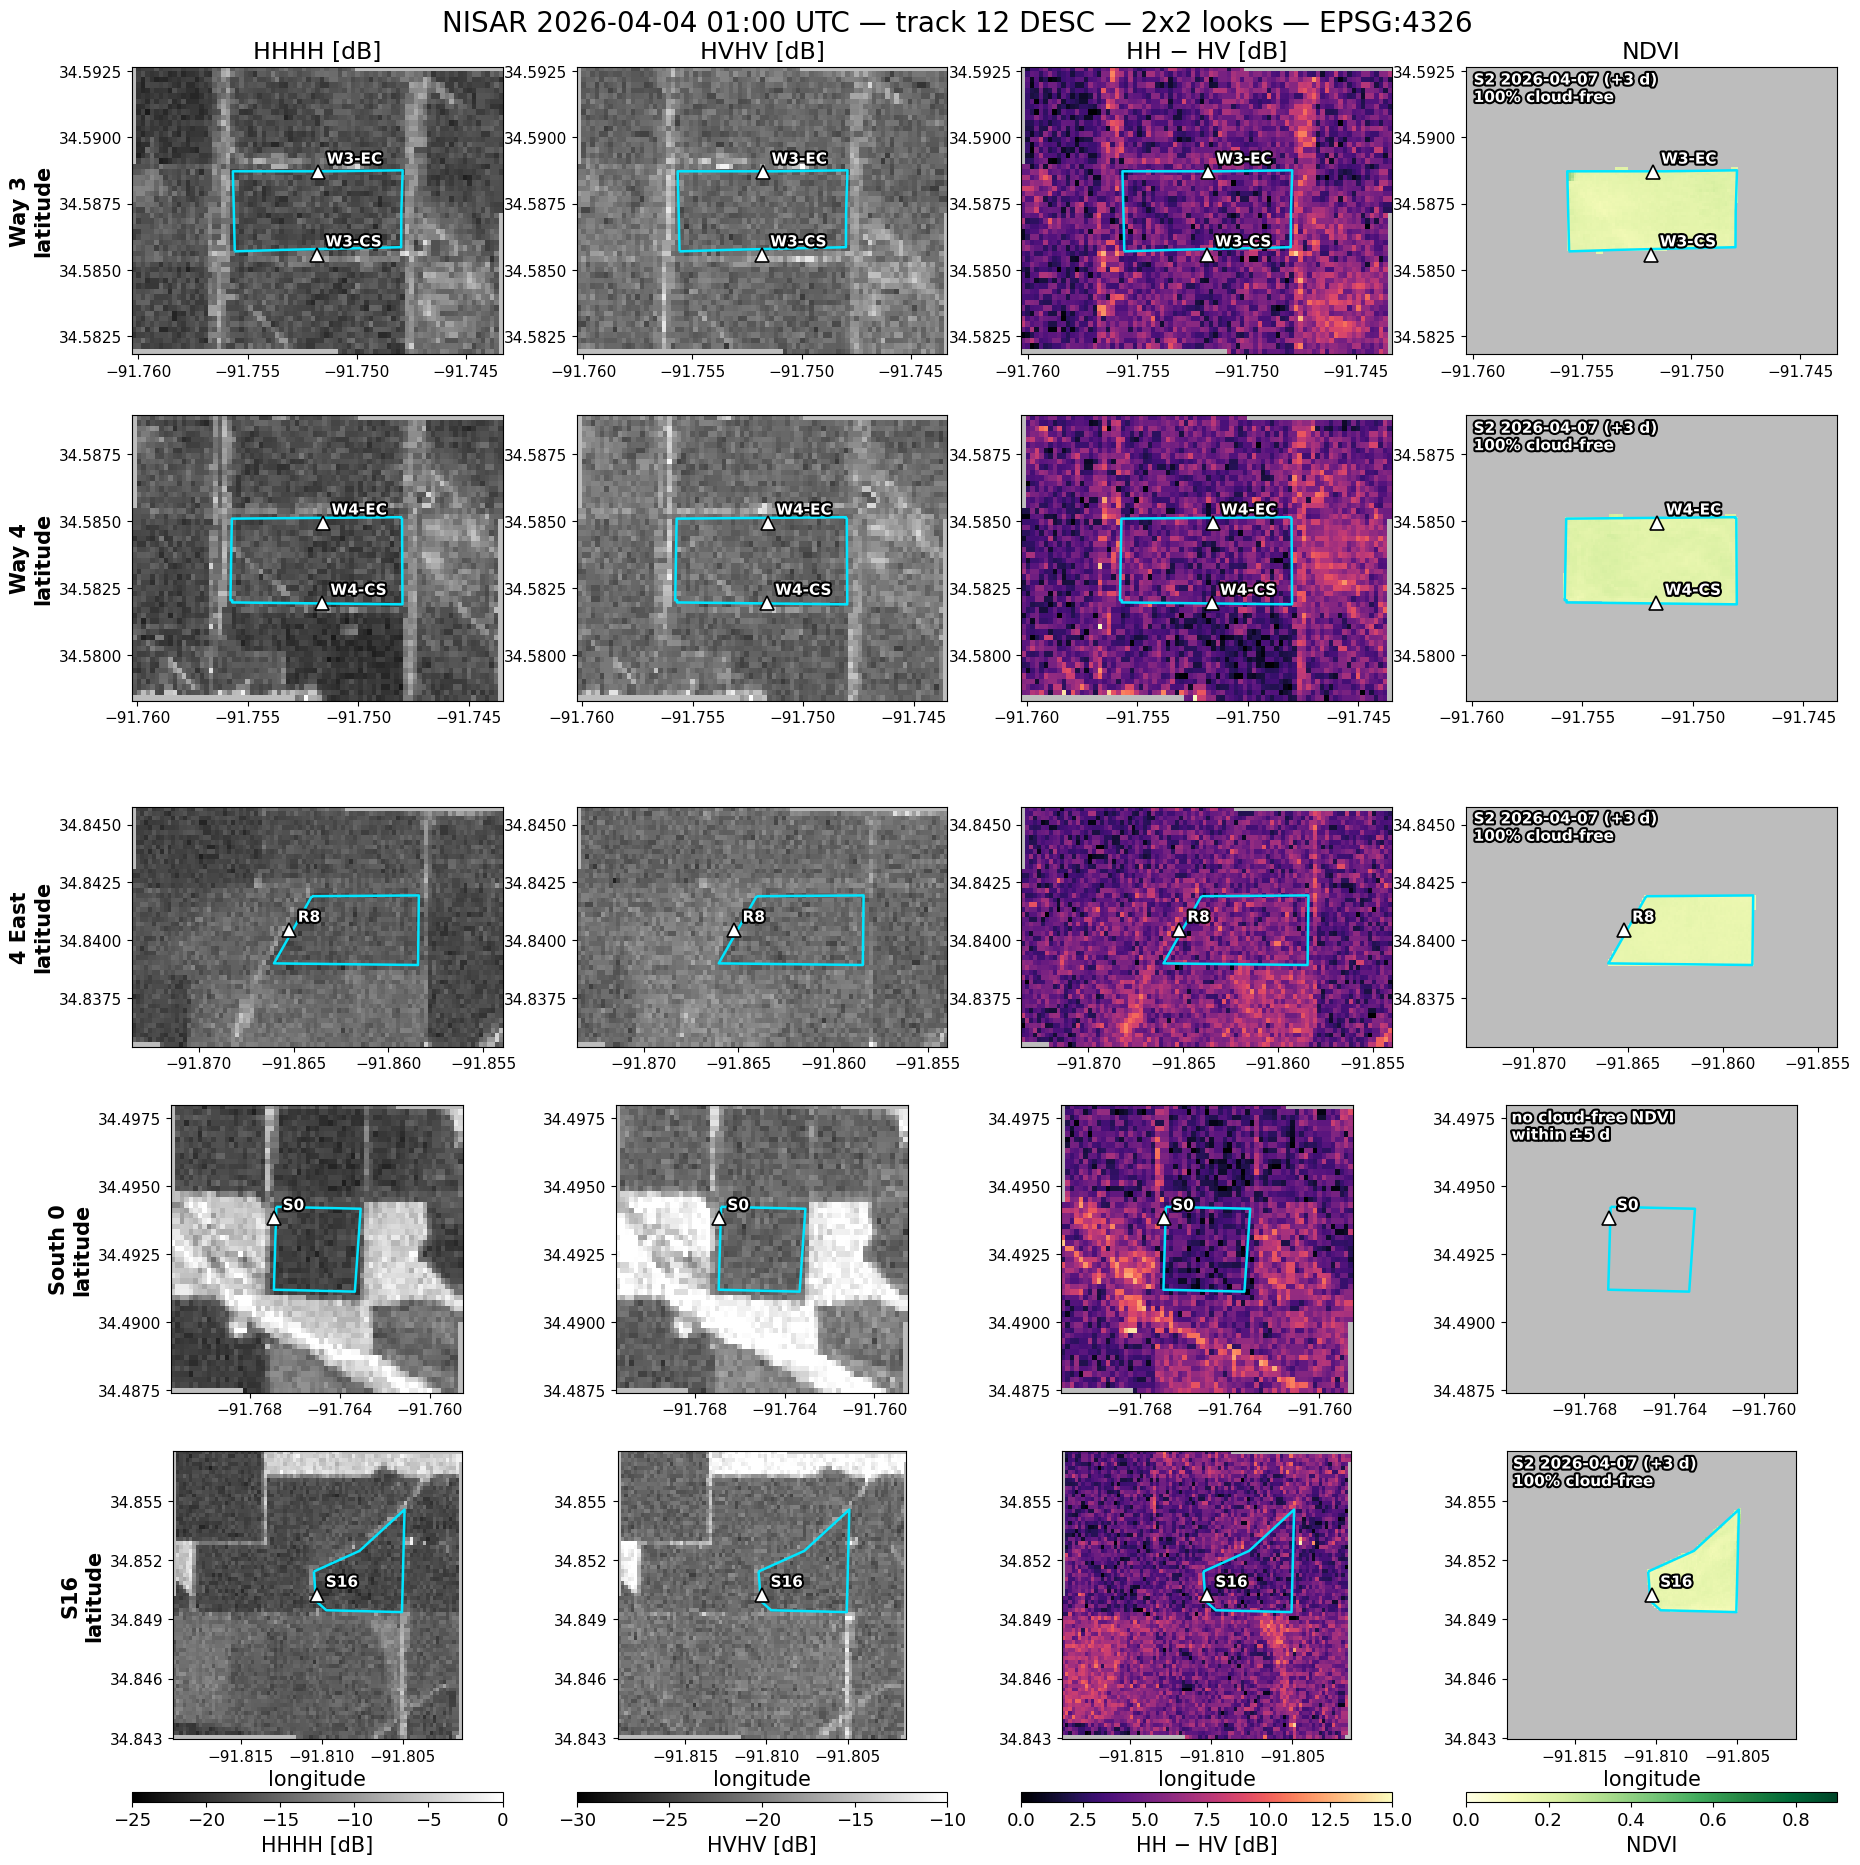

saved 38 figures to /Users/edliao/Documents/6_Projects/rice-methane-downscaling/outputs/nisar_field_maps_2026


In [ ]:
PANELS = [("HHHH", "HHHH [dB]", "gray"), ("HVHV", "HVHV [dB]", "gray"),
          ("ratio", "HH − HV [dB]", "magma"), ("ndvi", "NDVI", "YlGn")]
VLIM["ndvi"] = NDVI_VLIM


def nearest_ndvi(field, when):
    """Closest cloud-free NDVI date to `when` for this field, within NDVI_MAX_GAP_DAYS; else None."""
    cand = ndvi_means[(ndvi_means.field == field) & ndvi_means.ndvi.notna()]
    if cand.empty:
        return None
    gap = (cand.date - when.normalize()).abs()
    i = gap.idxmin()
    return cand.date[i] if gap[i] <= pd.Timedelta(days=NDVI_MAX_GAP_DAYS) else None


def corner_note(ax, text):
    ax.text(0.02, 0.98, text, transform=ax.transAxes, va="top", fontsize=11,
            color="white", fontweight="bold", path_effects=OUTLINE)


def plot_maps(ps):
    """One figure for one NISAR pass (a row of `passes`): a row per field, four columns."""
    fig, axes = plt.subplots(len(fields), len(PANELS), figsize=(22, 4.6 * len(fields)),
                             squeeze=False)
    ims = [None] * len(PANELS)
    for i, (_, fld) in enumerate(fields.iterrows()):
        axes[i][0].set_ylabel(f"{fld.field}\nlatitude", fontweight="bold")
        for ax in axes[i]:
            ax.set_facecolor("#bdbdbd")                  # NaN / outside data shows grey
        path = clip_path(ps.granule, fld.field)
        if path is None:                                 # field not covered by this pass
            for ax in axes[i]:
                ax.text(0.5, 0.5, "no data this pass", ha="center", transform=ax.transAxes)
                ax.set_xticks([]); ax.set_yticks([])
            continue
        w = map_layers(path)

        # Columns 1-3: NISAR.
        for j, (key, label, cmap) in enumerate(PANELS[:3]):
            ax = axes[i][j]
            ims[j] = ax.imshow(w[key], extent=w["extent"], cmap=cmap, interpolation="nearest",
                               vmin=VLIM[key][0], vmax=VLIM[key][1])
            decorate(ax, fld, w["extent"])

        # Column 4: NDVI from the closest cloud-free date, drawn in the SAME view.
        ax = axes[i][3]
        d = nearest_ndvi(fld.field, ps.acq_utc)
        if d is None:
            corner_note(ax, f"no cloud-free NDVI\nwithin ±{NDVI_MAX_GAP_DAYS} d")
        else:
            arr, dates, tf, crs = ndvi_stacks[fld.field]
            a, ext = warp_to_4326(arr[dates.index(d)], tf, crs)
            ims[3] = ax.imshow(a, extent=ext, cmap="YlGn", interpolation="nearest",
                               vmin=NDVI_VLIM[0], vmax=NDVI_VLIM[1])
            gap = (d - ps.acq_utc.normalize()).days
            frac = ndvi_means.loc[(ndvi_means.field == fld.field) & (ndvi_means.date == d), "valid_frac"].iloc[0]
            corner_note(ax, f"S2 {d:%Y-%m-%d} ({gap:+d} d)\n{frac:.0%} cloud-free")
        decorate(ax, fld, w["extent"])                   # same lon/lat window as the NISAR panels

    for j, (key, label, _) in enumerate(PANELS):
        axes[0][j].set_title(label)
        axes[-1][j].set_xlabel("longitude")
        if ims[j] is not None:                           # one colourbar per column
            fig.colorbar(ims[j], ax=axes[:, j].tolist(), orientation="horizontal",
                         pad=0.03, fraction=0.025, aspect=40, label=label)
    fig.canvas.draw()                                    # title just above the first row
    top = max(ax.get_position().y1 for ax in axes[0])
    fig.suptitle(f"NISAR {ps.acq_utc:%Y-%m-%d %H:%M} UTC — track {ps.track} {ps.direction}"
                 f" — {MAP_LOOKS}x{MAP_LOOKS} looks — EPSG:4326", y=top + 0.025)
    return fig


for k in MAP_DATES:                                      # show selected passes inline
    if k < len(passes):
        plot_maps(passes.iloc[k]); plt.show()

if SAVE_ALL_MAPS:                                        # one PNG per pass
    MAP_DIR.mkdir(parents=True, exist_ok=True)
    for _, ps in passes.iterrows():
        fig = plot_maps(ps)
        fig.savefig(MAP_DIR / f"{ps.acq_utc:%Y%m%d}_T{ps.track}_{ps.direction}.png",
                    dpi=110, bbox_inches="tight")
        plt.close(fig)
    print(f"saved {len(passes)} figures to {MAP_DIR}")